In [1]:

import pandas as pd

file_path = "/content/API_SP.POP.TOTL_DS2_en_csv_v2_38144.csv"

df = pd.read_csv(file_path, skiprows=4)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()


Dataset loaded successfully!
Shape: (266, 70)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,Unnamed: 69
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107624.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130075728.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0,769294618.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0,521764076.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,NaN


In [2]:

print(df.columns.tolist())


['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', 'Unnamed: 69']


In [3]:

print(df[['Country Name', '2023']].head(10))
print("Missing values in 2023:", df['2023'].isna().sum())


                  Country Name         2023
0                        Aruba     107359.0
1  Africa Eastern and Southern  750503764.0
2                  Afghanistan   41454761.0
3   Africa Western and Central  509398589.0
4                       Angola   36749906.0
5                      Albania    2745972.0
6                      Andorra      80856.0
7                   Arab World  482105978.0
8         United Arab Emirates   10483751.0
9                    Argentina   45538401.0
Missing values in 2023: 1


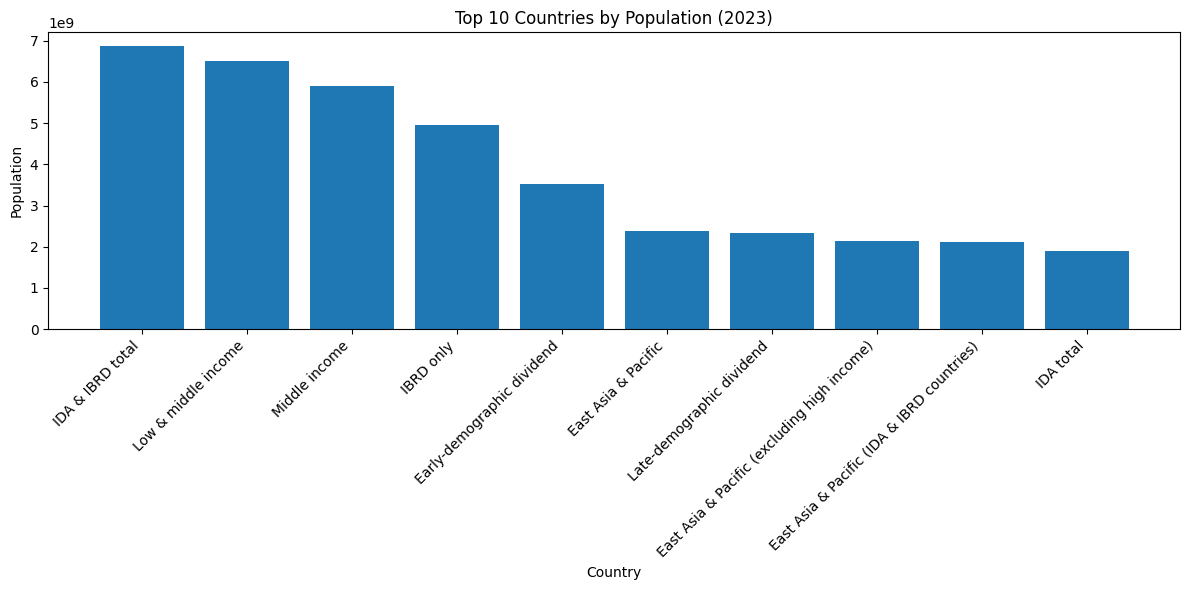

In [4]:

import matplotlib.pyplot as plt

pop_2023 = df[['Country Name', '2023']].dropna().copy()

aggregates = [
    'Africa Eastern and Southern',
    'Africa Western and Central',
    'Arab World',
    'European Union',
    'World',
    'Low income',
    'Lower middle income',
    'Upper middle income',
    'High income'
]

pop_2023 = pop_2023[~pop_2023['Country Name'].isin(aggregates)]

top10 = pop_2023.sort_values('2023', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10['Country Name'], top10['2023'])

plt.title('Top 10 Countries by Population (2023)')
plt.xlabel('Country')
plt.ylabel('Population')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


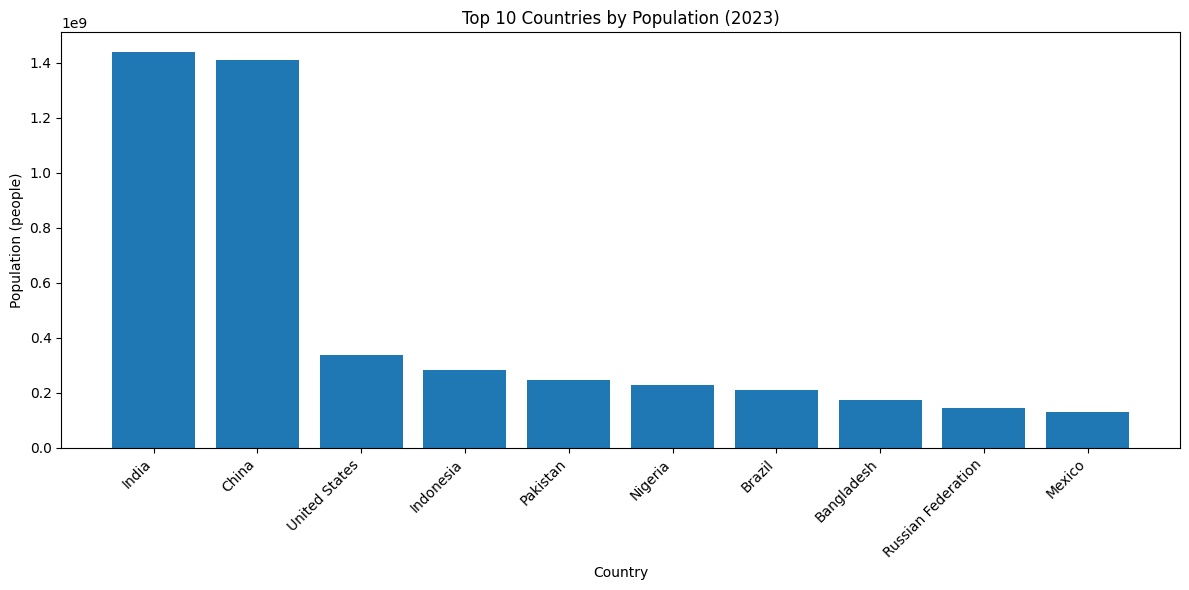

In [5]:

import matplotlib.pyplot as plt

exclude_codes = [
    'AFE', 'AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR',
    'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'FCS', 'HIC',
    'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'LAC',
    'LCN', 'LDC', 'LIC', 'LMC', 'LMY', 'LTE', 'MEA',
    'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PRE', 'PSS',
    'PST', 'SAS', 'SSA', 'SSF', 'SST', 'TEA', 'TEC',
    'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD'
]

countries = df[~df['Country Code'].isin(exclude_codes)].copy()
countries = countries.dropna(subset=['2023'])

top10 = countries.sort_values('2023', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10['Country Name'], top10['2023'])
plt.title('Top 10 Countries by Population (2023)')
plt.xlabel('Country')
plt.ylabel('Population (people)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


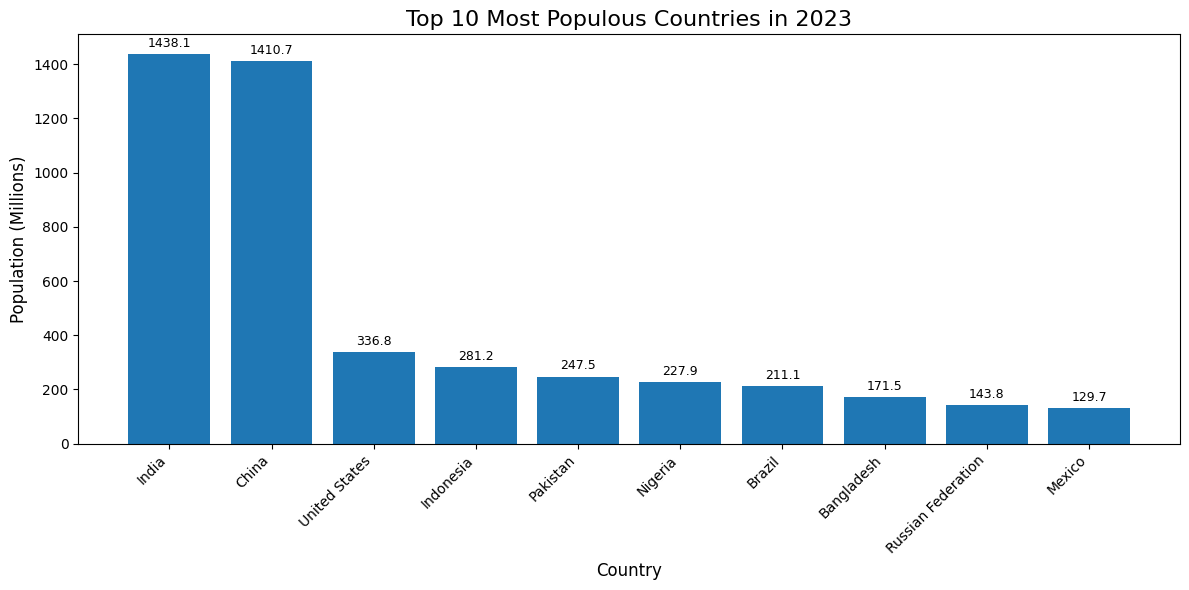

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

bars = plt.bar(top10['Country Name'], top10['2023'] / 1_000_000)

plt.title('Top 10 Most Populous Countries in 2023', fontsize=16)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Population (Millions)', fontsize=12)
plt.xticks(rotation=45, ha='right')

plt.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)

plt.tight_layout()
plt.savefig('top10_population_2023.png', dpi=300, bbox_inches='tight')
plt.show()


# Task 1: Data Visualization — Population Analysis

## Objective
To create a bar chart showing the 10 most populous countries in 2023 using Python and Matplotlib.

## Dataset
The dataset is provided by the World Bank and contains population data for countries and regions across multiple years. For this analysis, the 2023 population column was selected.

## Tools and Libraries
- Python
- Pandas
- Matplotlib
- Google Colab

## Methodology
1. Loaded the World Bank population dataset using Pandas.
2. Examined the dataset columns and population values for 2023.
3. Removed rows with missing population values.
4. Excluded regional aggregates to focus on individual countries.
5. Sorted countries by population in descending order.
6. Selected the top 10 countries and created a bar chart using Matplotlib.
7. Displayed population values in millions for easier comparison.

## Key Observations
- India has the highest population among the selected countries, at approximately 1,438.1 million.
- China ranks second, at approximately 1,410.7 million.
- The United States ranks third, at approximately 336.8 million.
- Indonesia and Pakistan are also among the most populous countries.
- The chart makes differences in population across the selected countries easy to compare.

## Conclusion
This task demonstrates how data visualization can present population data clearly and effectively. A bar chart helps identify the most populous countries and compare their population sizes. Python, Pandas, and Matplotlib provide a simple workflow for preparing data and communicating findings visually.